# Weather Conditions and Bike-Sharing Demand in London

**Region:** London, United Kingdom  
**Domain:** Urban transportation and weather  
**Period:** 1 January 2015 to 31 December 2016

## Research question
How were daily temperature, precipitation, and wind speed associated with daily Santander Cycle hires in London during 2015–2016?

## Hypotheses
1. Higher temperatures are associated with more daily bicycle hires.
2. Higher precipitation is associated with fewer daily bicycle hires.
3. Higher wind speeds are associated with fewer daily bicycle hires.

## Data sources
1. Transport for London, *Number of Bicycle Hires*: https://data.london.gov.uk/dataset/number-of-bicycle-hires-2r84d
2. NASA POWER daily meteorological data: https://power.larc.nasa.gov/

> Place `tfl-daily-cycle-hires.xlsx` in the same folder as this notebook before running it.

In [1]:
from pathlib import Path
from io import StringIO
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)

## 1. Load and clean the two datasets

In [2]:
# Locate the TfL workbook. The additional paths make the notebook work in
# Jupyter, Google Colab, and the original workspace.
bike_candidates = [
    Path('data/tfl-daily-cycle-hires.xlsx'),
    Path('tfl-daily-cycle-hires.xlsx'),
    Path('upload/tfl-daily-cycle-hires.xlsx'),
    Path('/content/tfl-daily-cycle-hires.xlsx')
]
bike_file = next((p for p in bike_candidates if p.exists()), None)
if bike_file is None:
    raise FileNotFoundError(
        'Upload tfl-daily-cycle-hires.xlsx and place it in the same folder as this notebook.'
    )

# The official workbook contains title/summary rows above the daily table.
bike_raw = pd.read_excel(bike_file, sheet_name='Data', header=None)
bike = bike_raw.iloc[6:, [1, 2]].copy()
bike.columns = ['date', 'daily_hires']
bike['date'] = pd.to_datetime(bike['date'], errors='coerce')
bike['daily_hires'] = pd.to_numeric(bike['daily_hires'], errors='coerce')
bike = bike.dropna(subset=['date', 'daily_hires'])
bike = bike[bike['date'].between('2015-01-01', '2016-12-31')]

print(f'TfL file: {bike_file}')
print(f'TfL daily records: {len(bike)}')
bike.head()

TfL file: tfl-daily-cycle-hires.xlsx
TfL daily records: 731


,date,daily_hires
1622,2015-01-01,9615
1623,2015-01-02,15389
1624,2015-01-03,5779
1625,2015-01-04,9367
1626,2015-01-05,20566


In [3]:
# NASA POWER point data for central London (51.5074, -0.1278).


weather_url = (
    'https://power.larc.nasa.gov/api/temporal/daily/point'
    '?parameters=T2M,PRECTOTCORR,WS2M'
    '&community=RE&longitude=-0.1278&latitude=51.5074'
    '&start=20150101&end=20161231&format=CSV'
)


# NASA places metadata above the CSV header, so locate the header automatically.
weather_text = urlopen(weather_url, timeout=60).read().decode('utf-8')
weather_lines = weather_text.splitlines()
header_row = next(i for i, line in enumerate(weather_lines) if line.startswith('YEAR,'))
weather = pd.read_csv(StringIO('\n'.join(weather_lines[header_row:])))

weather['date'] = pd.to_datetime(
    dict(year=weather['YEAR'], month=weather['MO'], day=weather['DY'])
)
weather = weather.rename(columns={
    'T2M': 'temperature_c',
    'PRECTOTCORR': 'precipitation_mm',
    'WS2M': 'wind_speed_ms'
})[['date', 'temperature_c', 'precipitation_mm', 'wind_speed_ms']]
weather = weather.replace(-999, np.nan)

print(f'NASA daily records: {len(weather)}')
weather.head()

NASA daily records: 731


,date,temperature_c,precipitation_mm,wind_speed_ms
0,2015-01-01,7.34,0.77,6.62
1,2015-01-02,6.46,0.47,4.60
2,2015-01-03,3.40,13.37,2.34
3,2015-01-04,0.48,0.10,1.31
4,2015-01-05,5.88,0.41,2.33


## 2. Merge by date and check data quality

In [4]:
data = (
    bike.merge(weather, on='date', how='inner', validate='one_to_one')
        .sort_values('date')
        .reset_index(drop=True)
)

quality_check = pd.Series({
    'Merged rows': len(data),
    'First date': data['date'].min().date(),
    'Last date': data['date'].max().date(),
    'Duplicate dates': data['date'].duplicated().sum(),
    'Missing values': data.isna().sum().sum()
})
display(quality_check.to_frame('Result'))
data.head()

,Result
Merged rows,731
First date,2015-01-01
Last date,2016-12-31
Duplicate dates,0
Missing values,0


,date,daily_hires,temperature_c,precipitation_mm,wind_speed_ms
0,2015-01-01,9615,7.34,0.77,6.62
1,2015-01-02,15389,6.46,0.47,4.60
2,2015-01-03,5779,3.40,13.37,2.34
3,2015-01-04,9367,0.48,0.10,1.31
4,2015-01-05,20566,5.88,0.41,2.33


## 3. Descriptive statistics and correlations

In [5]:
variables = ['daily_hires', 'temperature_c', 'precipitation_mm', 'wind_speed_ms']
display(data[variables].describe().round(2))

,daily_hires,temperature_c,precipitation_mm,wind_speed_ms
count,731.00,731.00,731.00,731.00
mean,27599.83,10.37,1.87,3.46
std,8712.58,5.25,3.62,1.50
min,4894.00,-1.70,0.00,0.69
25%,22275.50,6.20,0.10,2.40
50%,27357.00,10.35,0.42,3.20
75%,34045.00,14.62,2.17,4.31
max,73094.00,23.20,49.06,9.62


In [6]:
correlation_rows = []
for variable in ['temperature_c', 'precipitation_mm', 'wind_speed_ms']:
    pearson_r, pearson_p = pearsonr(data[variable], data['daily_hires'])
    spearman_r, spearman_p = spearmanr(data[variable], data['daily_hires'])
    correlation_rows.append({
        'Weather variable': variable,
        'Pearson r': pearson_r,
        'Pearson p-value': pearson_p,
        'Spearman rho': spearman_r,
        'Spearman p-value': spearman_p
    })

correlations = pd.DataFrame(correlation_rows).set_index('Weather variable')
display(correlations.round(4))

,Pearson r,Pearson p-value,Spearman rho,Spearman p-value
Weather variable,,,,
temperature_c,0.6663,0.0,0.6969,0.0
precipitation_mm,-0.3449,0.0,-0.4838,0.0
wind_speed_ms,-0.3447,0.0,-0.3156,0.0


## 4. Main visualizations
The scatter plots show the direction and strength of the relationships. Each red line is a fitted linear trend.

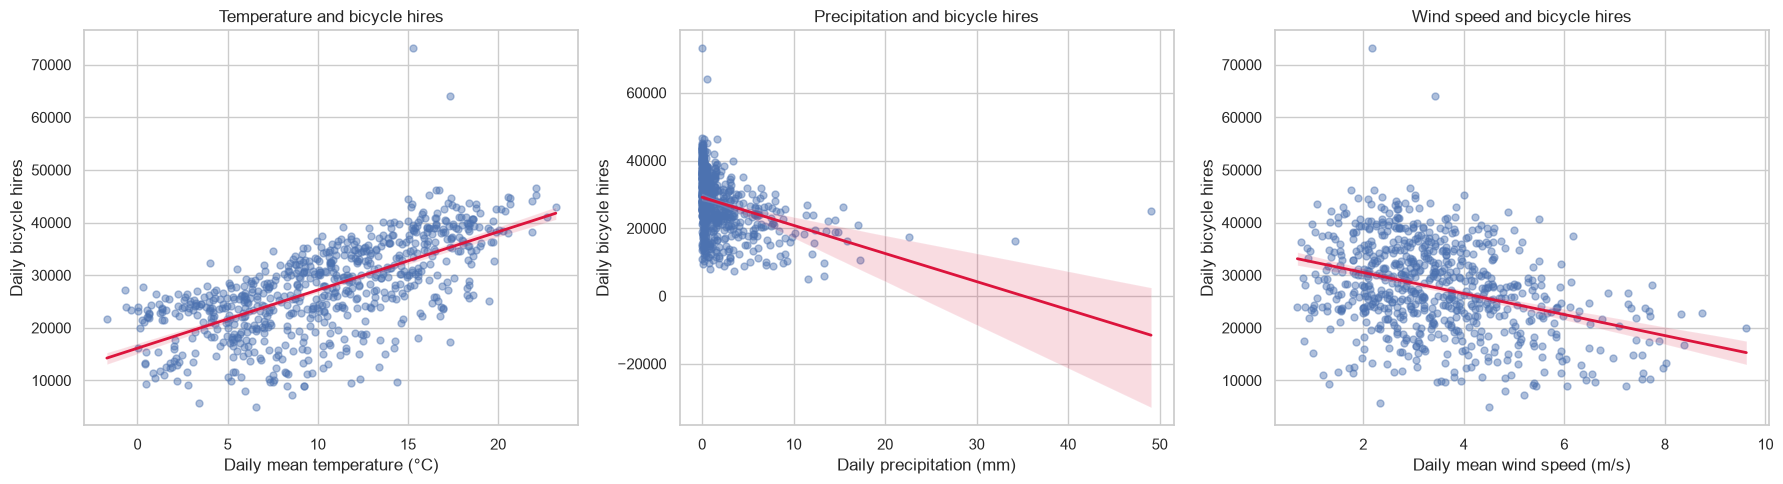

In [7]:
plot_settings = [
    ('temperature_c', 'Daily mean temperature (°C)', 'Temperature and bicycle hires'),
    ('precipitation_mm', 'Daily precipitation (mm)', 'Precipitation and bicycle hires'),
    ('wind_speed_ms', 'Daily mean wind speed (m/s)', 'Wind speed and bicycle hires')
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x, xlabel, title) in zip(axes, plot_settings):
    sns.regplot(
        data=data, x=x, y='daily_hires', ax=ax,
        scatter_kws={'alpha': 0.45, 's': 25},
        line_kws={'color': 'crimson', 'linewidth': 2}
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Daily bicycle hires')

plt.tight_layout()
plt.show()

## 5. Intuitive group comparisons

In [8]:
# Define a rain day as at least 1 mm of precipitation.
data['weather_group'] = np.where(
    data['precipitation_mm'] >= 1, 'Rain day (≥1 mm)', 'Dry/nearly dry day (<1 mm)'
)
rain_summary = (
    data.groupby('weather_group')['daily_hires']
        .agg(days='count', mean_hires='mean', median_hires='median')
        .round(1)
)
display(rain_summary)

dry_mean = rain_summary.loc['Dry/nearly dry day (<1 mm)', 'mean_hires']
rain_mean = rain_summary.loc['Rain day (≥1 mm)', 'mean_hires']
rain_reduction = (dry_mean - rain_mean) / dry_mean * 100
print(f'Average reduction on rain days: {rain_reduction:.1f}%')

,days,mean_hires,median_hires
weather_group,,,
Dry/nearly dry day (<1 mm),451,30142.0,30285.0
Rain day (≥1 mm),280,23505.2,23731.5


Average reduction on rain days: 22.0%


,days,mean_hires,median_hires
temperature_group,,,
≤5°C,122,20833.3,22839.5
5–10°C,221,22978.7,23677.0
10–15°C,218,28977.3,30075.0
>15°C,170,36697.0,38118.5


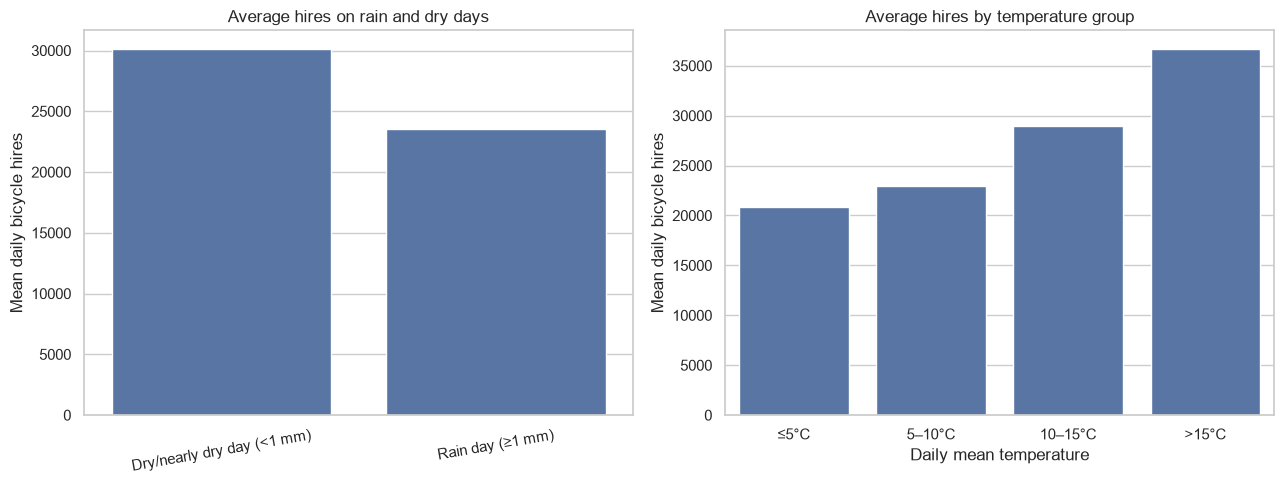

In [9]:
data['temperature_group'] = pd.cut(
    data['temperature_c'],
    bins=[-np.inf, 5, 10, 15, np.inf],
    labels=['≤5°C', '5–10°C', '10–15°C', '>15°C']
)
temperature_summary = (
    data.groupby('temperature_group', observed=True)['daily_hires']
        .agg(days='count', mean_hires='mean', median_hires='median')
        .round(1)
)
display(temperature_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=data, x='weather_group', y='daily_hires', errorbar=None, ax=axes[0])
axes[0].set_title('Average hires on rain and dry days')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mean daily bicycle hires')
axes[0].tick_params(axis='x', rotation=10)

sns.barplot(data=data, x='temperature_group', y='daily_hires', errorbar=None, ax=axes[1])
axes[1].set_title('Average hires by temperature group')
axes[1].set_xlabel('Daily mean temperature')
axes[1].set_ylabel('Mean daily bicycle hires')

plt.tight_layout()
plt.show()

## 6. Multiple regression with calendar controls
This model estimates the association of each weather variable with bicycle hires while controlling for day of the week, month, year, and the other weather variables. Standardized coefficients allow the three weather variables to be compared on the same scale.

In [10]:
data['day_of_week'] = data['date'].dt.dayofweek
data['month'] = data['date'].dt.month
data['year'] = data['date'].dt.year

weather_columns = ['temperature_c', 'precipitation_mm', 'wind_speed_ms']
calendar_controls = pd.get_dummies(
    data[['day_of_week', 'month', 'year']].astype(str),
    drop_first=True, dtype=float
)

weather_scaled = StandardScaler().fit_transform(data[weather_columns])
target_scaled = StandardScaler().fit_transform(data[['daily_hires']]).ravel()
X = np.column_stack([weather_scaled, calendar_controls.to_numpy()])

model = LinearRegression().fit(X, target_scaled)
regression_results = pd.DataFrame({
    'Weather variable': weather_columns,
    'Standardized coefficient': model.coef_[:3]
}).set_index('Weather variable')

display(regression_results.round(3))
print(f'Model R²: {model.score(X, target_scaled):.3f}')

,Standardized coefficient
Weather variable,
temperature_c,0.422
precipitation_mm,-0.343
wind_speed_ms,-0.169


Model R²: 0.783


## 7. Automatic conclusion

In [11]:
temp_r = correlations.loc['temperature_c', 'Pearson r']
rain_r = correlations.loc['precipitation_mm', 'Pearson r']
wind_r = correlations.loc['wind_speed_ms', 'Pearson r']

print('RESULTS')
print(f'1. Temperature and hires: r = {temp_r:.3f} (positive association).')
print(f'2. Precipitation and hires: r = {rain_r:.3f} (negative association).')
print(f'3. Wind speed and hires: r = {wind_r:.3f} (negative association).')
print(f'4. Rain days had approximately {rain_reduction:.1f}% fewer hires on average.')
print('All three hypotheses are supported by the observed data.')

RESULTS
1. Temperature and hires: r = 0.666 (positive association).
2. Precipitation and hires: r = -0.345 (negative association).
3. Wind speed and hires: r = -0.345 (negative association).
4. Rain days had approximately 22.0% fewer hires on average.
All three hypotheses are supported by the observed data.


## Interpretation and limitations
The results show that warmer days were associated with more bicycle hires, whereas wetter and windier days were associated with fewer hires. These patterns remained in the same direction after calendar factors and the other weather variables were included in a multiple regression model. The visualizations therefore directly address the research question and support all three hypotheses.

The analysis demonstrates association rather than causation. NASA POWER provides model-based meteorological data for a grid point representing central London rather than measurements from every location in the city. Other factors, such as holidays, public events, transport disruptions, and changes in the cycle-hire system, may also influence daily bicycle demand.